# Rain Prediction — XGBoost

Gradient-boosted tree pipeline for predicting next-day rainfall (`RainTomorrow`), branché
directement sur les sorties du pipeline de preprocessing du dépôt :

| Notebook | Sortie consommée ici |
|---|---|
| `3.preprocessing_trend_group.ipynb` | `data/weatherAUS_trend_grouped.csv` |
| `4_preprocessing_imputation.ipynb`  | `data/weatherAUS_MICE_cyclic.csv`, `data/weatherAUS_{X,y}_{train,test}.csv` |

Le split chronologique (`< 2016-01-01` / `>= 2016-01-01`), l'imputation MICE par groupe de
tendance, l'encodage cyclique des directions de vent, le `LabelEncoder` et le `RobustScaler`
sont **entièrement délégués au pipeline** : ce notebook ne resplitte ni ne réimpute rien, il
consomme `weatherAUS_X_train.csv` / `weatherAUS_y_train.csv` / `weatherAUS_X_test.csv` /
`weatherAUS_y_test.csv` comme le font `5.modelisation_light_gbm.ipynb` et
`5.modelisation_linear_svm.ipynb`.

Numerical outputs are mirrored to `XGB_result.txt`; every figure is saved as a PNG under
`figures/`; **chaque modèle entraîné est sérialisé dans `../../models/` avec `joblib`**.


## 1. Colab setup, imports and constants

In [12]:
# --- Environnement ---
# Ce notebook tourne en local sur les sorties du pipeline de preprocessing
# (dossier ../../data). Sur Colab, installer les dépendances puis pointer
# WEATHER_DATA_DIR vers le dossier contenant les CSV du pipeline.
import subprocess, sys as _sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run([_sys.executable, '-m', 'pip', '-q', 'install', '-U', 'xgboost', 'shap'],
                   check=False)
    subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version',
                    '--format=csv,noheader'], check=False)

print(f'Running on Colab: {IN_COLAB}')


In [13]:
import os
import sys
import zipfile
import warnings
from datetime import datetime, timezone

import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    RandomizedSearchCV, TimeSeriesSplit, learning_curve,
)
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score,
    roc_curve, roc_auc_score, precision_recall_curve, auc,
    brier_score_loss, log_loss,
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

import xgboost as xgb
from xgboost import XGBClassifier

# When the model lives on GPU but the input frame is on host, XGBoost warns on every
# predict. It is harmless here; silence it to keep the log readable.
warnings.filterwarnings('ignore', category=UserWarning, module='xgboost')

# Optional dependencies — degrade gracefully if missing.
try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except ImportError:
    HAS_SMOTE = False

RANDOM_STATE = 42
TEST_CUTOFF = pd.Timestamp('2016-01-01')   # train < cutoff <= test

# --- GPU configuration ---------------------------------------------------------
def _gpu_available():
    """Probe for a usable CUDA device by training a 1-round model on it."""
    try:
        dtest = xgb.DMatrix(np.zeros((8, 2)), label=np.zeros(8))
        xgb.train({'device': 'cuda', 'tree_method': 'hist'}, dtest, num_boost_round=1)
        return True
    except Exception as e:
        print(f'CUDA probe failed ({type(e).__name__}); falling back to CPU.')
        return False

USE_GPU = _gpu_available()
DEVICE = 'cuda' if USE_GPU else 'cpu'
# A single GPU cannot be shared across parallel CV workers without contention/OOM,
# so on GPU we run CV folds sequentially (each fit still uses the GPU). On CPU we
# fan out across cores instead.
SEARCH_N_JOBS = 1 if USE_GPU else -1

XGB_KW = dict(
    tree_method='hist',
    device=DEVICE,
    eval_metric='logloss',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

def make_xgb(**overrides):
    """XGBClassifier carrying the shared device/seed config; overrides win."""
    params = dict(XGB_KW)
    params.update(overrides)
    return XGBClassifier(**params)

print(f'xgboost {xgb.__version__} | device: {DEVICE} | search n_jobs: {SEARCH_N_JOBS}')
print(f'shap: {HAS_SHAP} | imblearn(SMOTE): {HAS_SMOTE}')

### Output setup

A `figures/` directory and an `XGB_result.txt` file are created next to this notebook.
`sys.stdout` is teed so every `print(...)` is mirrored to the results file. Each plot is
saved with `save_fig(...)` before `plt.show()`, et chaque modèle entraîné est sérialisé avec
`save_model(...)` dans `../../models/` (dossier `models/` du dépôt).


In [14]:
# Create output locations
os.makedirs('figures', exist_ok=True)

_XGB_RESULT_PATH = 'XGB_result.txt'
_XGB_RESULT_FILE = open(_XGB_RESULT_PATH, 'w', encoding='utf-8')

class _Tee:
    """Write to both real stdout and the results file."""
    def __init__(self, *streams):
        self._streams = streams
    def write(self, data):
        for s in self._streams:
            s.write(data)
    def flush(self):
        for s in self._streams:
            s.flush()
    def isatty(self):
        return False

_ORIG_STDOUT = sys.stdout
sys.stdout = _Tee(_ORIG_STDOUT, _XGB_RESULT_FILE)

print('# XGBoost — numerical outputs')
print(f'# Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')

def log_section(title):
    """Print a section banner so XGB_result.txt is easy to skim."""
    bar = '=' * 72
    print(f'\n{bar}\n{title}\n{bar}')

def save_fig(name, fig=None):
    """Save the current (or given) figure to figures/<name>.png at 150 dpi."""
    if fig is None:
        fig = plt.gcf()
    path = f'figures/{name}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'  [saved {path}]')

# --- Sérialisation des modèles ---------------------------------------------
# Chaque étape du notebook est enregistrée dans <repo>/models sous forme d'un
# dict joblib : le modèle + les métadonnées nécessaires pour le rejouer.
MODEL_DIR = os.environ.get('WEATHER_MODEL_DIR', '../../models')
os.makedirs(MODEL_DIR, exist_ok=True)
NOTEBOOK = 'EXP-001_XGBoost'

def save_model(obj, name, **meta):
    """Sauvegarde `obj` dans MODEL_DIR/<name>.joblib avec ses métadonnées."""
    path = f'{MODEL_DIR}/{name}.joblib'
    joblib.dump({'model': obj,
                 'notebook': NOTEBOOK,
                 'created_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
                 **meta}, path)
    print(f'  [saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)]')


Running on Colab: True
xgboost 3.4.0 | device: cuda | search n_jobs: 1
shap: True | imblearn(SMOTE): True
# XGBoost — numerical outputs
# Generated: 2026-08-11 12:32:20

2. Data loading (sorties du pipeline)
X_train (113506, 29) | X_test (25314, 29)
Train 2007-11-01 -> 2015-12-31 | Test 2016-01-01 -> 2017-06-25
Stations : 49 | pluie train 21.9574% / test 22.6950%
<xml><var name="_dummy_ipython_val"  />
<var name="_dummy_special_var"  />
<var name="DATA_DIR" type="str" qualifier="builtins" value="../../data" />
<var name="DEVICE" type="str" qualifier="builtins" value="cuda" />
<var name="DROP_COLS" type="list" qualifier="builtins" value="%5B%27WindGustDir%27%2C %27WindDir9am%27%2C %27WindDir3pm%27%2C %27RainToday%27%2C %27Humidity9am%27%2C %27Month%27%5D" isContainer="True" shape="6" />
<var name="FEATURES" type="list" qualifier="builtins" value="%5B%27MinTemp%27%2C %27MaxTemp%27%2C %27Rainfall%27%2C %27Evaporation%27%2C %27Sunshine%27%2C %27WindGustSpeed%27%2C %27WindSpeed9am%27%2C %27

## 2. Data loading

In [15]:
log_section('2. Data loading (sorties du pipeline)')

# Sorties du pipeline, dans <repo>/data :
#   3.preprocessing_trend_group.ipynb -> weatherAUS_trend_grouped.csv
#   4_preprocessing_imputation.ipynb  -> weatherAUS_MICE_cyclic.csv
#                                        weatherAUS_X_train.csv / weatherAUS_y_train.csv
#                                        weatherAUS_X_test.csv  / weatherAUS_y_test.csv
DATA_DIR = os.environ.get('WEATHER_DATA_DIR', '../../data')

# Matrices déjà splitées, encodées (LabelEncoder) et scalées (RobustScaler ajusté
# sur le train uniquement) par 4_preprocessing_imputation.ipynb.
X_train = pd.read_csv(f'{DATA_DIR}/weatherAUS_X_train.csv')
X_test  = pd.read_csv(f'{DATA_DIR}/weatherAUS_X_test.csv')
y_train = pd.read_csv(f'{DATA_DIR}/weatherAUS_y_train.csv').squeeze('columns').astype(int)
y_test  = pd.read_csv(f'{DATA_DIR}/weatherAUS_y_test.csv').squeeze('columns').astype(int)

# Index (Date, Location) aligné ligne à ligne sur X_train / X_test :
# weatherAUS_MICE_cyclic.csv est trié par Date et le pipeline y applique le même
# seuil TEST_CUTOFF, donc ses len(X_train) premières lignes SONT celles de X_train.
meta = pd.read_csv(f'{DATA_DIR}/weatherAUS_MICE_cyclic.csv',
                   usecols=['Date', 'Location'], parse_dates=['Date'])
meta = meta[['Date', 'Location']]
assert len(meta) == len(X_train) + len(X_test), 'X_train/X_test ne recouvrent pas MICE_cyclic'
meta_train = meta.iloc[:len(X_train)].reset_index(drop=True)
meta_test  = meta.iloc[len(X_train):].reset_index(drop=True)
assert (meta_train['Date'] < TEST_CUTOFF).all(), 'lignes de train postérieures au seuil'
assert (meta_test['Date'] >= TEST_CUTOFF).all(), 'lignes de test antérieures au seuil'

print(f'X_train {X_train.shape} | X_test {X_test.shape}')
print(f'Train {meta_train["Date"].min().date()} -> {meta_train["Date"].max().date()} | '
      f'Test {meta_test["Date"].min().date()} -> {meta_test["Date"].max().date()}')
print(f'Stations : {meta["Location"].nunique()} | pluie train {y_train.mean():.4%} / test {y_test.mean():.4%}')


## 3. Sélection des features

Le pipeline fournit une matrice de 29 colonnes déjà imputée, encodée et scalée. On applique
ici la **même drop-list que l'étude de régression logistique** pour retomber sur la matrice
de **23 features** utilisée par toutes les expériences XGBoost, afin que les EXP-001..007
restent comparables entre elles.

**Aucun `StandardScaler` n'est ajouté** : le pipeline a déjà appliqué un `RobustScaler`
(ajusté sur le train uniquement), et les arbres de gradient boosting sont de toute façon
invariants à toute transformation monotone appliquée colonne par colonne.


In [16]:
log_section('3. Sélection des features')

# Le pipeline livre 29 colonnes. On retire les mêmes que l'étude LR pour que les
# expériences EXP-001..007 restent comparables entre elles :
DROP_COLS = [
    'WindGustDir', 'WindDir9am', 'WindDir3pm',  # labels encodés ; les sin/cos sont conservés
    'RainToday',                                # quasi-fuite (on donne déjà le reste de la journée)
    'Humidity9am',                              # on garde Humidity3pm (plus prédictive)
    'Month',                                    # redondant avec Date_sin / Date_cos
]
FEATURES = [c for c in X_train.columns if c not in DROP_COLS]
X_train = X_train[FEATURES]
X_test  = X_test[FEATURES]

print(f'Feature matrix: {X_train.shape}')
print(f'Columns ({len(FEATURES)}):')
for c in FEATURES:
    print(f'  - {c}')

y_full = pd.concat([y_train, y_test], ignore_index=True)
print('\nClass distribution (RainTomorrow):')
print(y_full.value_counts().to_string())
print(f'Rain proportion: {y_full.mean():.4f}')


## 4. Split chronologique (fourni par le pipeline)

Le découpage `train < 2016-01-01 <= test` est celui réalisé par
`4_preprocessing_imputation.ipynb`, **avant** l'imputation MICE (les imputers sont ajustés
sur le train puis appliqués au test). Rien n'est resplitté ici : cette section ne fait que
décrire le split reçu et en dériver `scale_pos_weight`.


In [17]:
log_section('4. Split chronologique (fourni par le pipeline)')

# XGBoost veut des labels entiers ; y_train / y_test le sont déjà (cast au chargement).
y_train_i = y_train
y_test_i  = y_test

print(f'Train: {len(X_train):,} rows | dates {meta_train["Date"].min().date()} to {meta_train["Date"].max().date()}')
print(f'Test : {len(X_test):,} rows | dates {meta_test["Date"].min().date()} to {meta_test["Date"].max().date()}')
print(f'Train rain proportion: {y_train.mean():.4%}')
print(f'Test  rain proportion: {y_test.mean():.4%}')
print(f'Drift (test - train) : {(y_test.mean() - y_train.mean()) * 100:+.2f} percentage points')

# Inverse class ratio used for scale_pos_weight downstream.
pos_rate = float(y_train.mean())
SPW = (1 - pos_rate) / pos_rate
print(f'scale_pos_weight (neg/pos) = {SPW:.4f}')

ts_cv = TimeSeriesSplit(n_splits=5)


## 5. Baseline model

Untuned `XGBClassifier` with library defaults, no imbalance reweighting, evaluated at the
default 0.5 threshold. Establishes the tree-ensemble floor (LR baseline F1 was 0.61).

In [18]:
log_section('5. Baseline model')

baseline = make_xgb()
baseline.fit(X_train, y_train_i)

y_pred_baseline = baseline.predict(X_test)
y_proba_baseline = baseline.predict_proba(X_test)[:, 1]

print('Baseline classification report:')
print(classification_report(y_test_i, y_pred_baseline))
print(f'ROC-AUC: {roc_auc_score(y_test_i, y_proba_baseline):.4f}')

save_model(baseline, 'EXP-001_01_baseline',
           features=FEATURES, stage='baseline (defaults, no reweighting)',
           test_roc_auc=float(roc_auc_score(y_test_i, y_proba_baseline)))


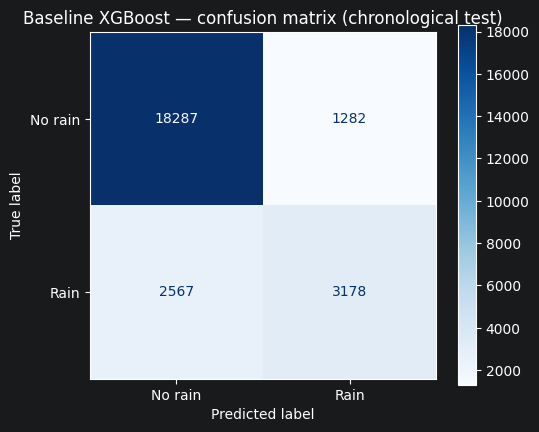

In [19]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm = confusion_matrix(y_test_i, y_pred_baseline)
ConfusionMatrixDisplay(cm, display_labels=['No rain', 'Rain']).plot(cmap='Blues', ax=ax)
ax.set_title('Baseline XGBoost — confusion matrix (chronological test)')
plt.tight_layout()
save_fig('01_baseline_confusion_matrix', fig)
plt.show()

## 6. Hyperparameter tuning with TimeSeriesSplit

`RandomizedSearchCV` over the XGBoost grid, scored on rain-class F1, with
`TimeSeriesSplit(5)` folds. `scale_pos_weight` is searched jointly with the tree
hyperparameters. Random (not exhaustive) search because the grid is ~100k configurations.

In [20]:
log_section('6. Hyperparameter tuning')

param_dist = {
    'n_estimators':     [200, 400, 600, 800],
    'max_depth':        [3, 4, 5, 6, 8],
    'learning_rate':    [0.01, 0.03, 0.05, 0.1],
    'subsample':        [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma':            [0, 0.1, 0.5],
    'reg_lambda':       [1, 5, 10],
    'scale_pos_weight': [1, SPW],
}

N_ITER = 30
xgb_base = make_xgb()

search = RandomizedSearchCV(
    xgb_base, param_dist,
    n_iter=N_ITER,
    scoring='f1',
    cv=ts_cv,
    n_jobs=SEARCH_N_JOBS,   # 1 on GPU (sequential folds), -1 on CPU
    random_state=RANDOM_STATE,
    verbose=1,
)
search.fit(X_train, y_train_i)

best_model = search.best_estimator_
best_params = search.best_params_
print(f'Best params : {best_params}')
print(f'Best CV F1  : {search.best_score_:.4f}')

save_model(best_model, 'EXP-001_02_tuned',
           features=FEATURES, stage='RandomizedSearchCV (TimeSeriesSplit, scoring=f1)',
           best_params=best_params, cv_f1=float(search.best_score_), n_iter=N_ITER)


In [21]:
y_pred_tuned = best_model.predict(X_test)
y_proba_tuned = best_model.predict_proba(X_test)[:, 1]

print('Tuned model — classification report (threshold 0.5):')
print(classification_report(y_test_i, y_pred_tuned))
print(f'ROC-AUC: {roc_auc_score(y_test_i, y_proba_tuned):.4f}')

## 7. Class imbalance — strategies

Three handlings compared at a fixed reference configuration so the F1 deltas are
attributable to the imbalance mechanism: default (`scale_pos_weight=1`),
`scale_pos_weight=(1-p)/p`, and SMOTE (run only if `imbalanced-learn` is installed).

In [22]:
log_section('7. Class imbalance — strategies')

REF_PARAMS = dict(
    n_estimators=400, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
)

# 1) default (no reweighting)
m1 = make_xgb(scale_pos_weight=1, **REF_PARAMS).fit(X_train, y_train_i)
p1 = m1.predict(X_test)

# 2) scale_pos_weight = neg/pos
m2 = make_xgb(scale_pos_weight=SPW, **REF_PARAMS).fit(X_train, y_train_i)
p2 = m2.predict(X_test)

rows = [
    {'config': 'default', 'F1': f1_score(y_test_i, p1),
     'precision': precision_score(y_test_i, p1), 'recall': recall_score(y_test_i, p1)},
    {'config': 'scale_pos_weight', 'F1': f1_score(y_test_i, p2),
     'precision': precision_score(y_test_i, p2), 'recall': recall_score(y_test_i, p2)},
]

# 3) SMOTE (optional)
m3 = p3 = None
if HAS_SMOTE:
    sm = SMOTE(random_state=RANDOM_STATE)
    X_sm, y_sm = sm.fit_resample(X_train, y_train_i)
    print(f'SMOTE training set: {X_sm.shape[0]:,} rows ({y_sm.mean():.0%} rain)')
    m3 = make_xgb(scale_pos_weight=1, **REF_PARAMS).fit(X_sm, y_sm)
    p3 = m3.predict(X_test)
    rows.append({'config': 'SMOTE', 'F1': f1_score(y_test_i, p3),
                 'precision': precision_score(y_test_i, p3), 'recall': recall_score(y_test_i, p3)})
else:
    print('SMOTE skipped (imbalanced-learn not installed).')

imb_df = pd.DataFrame(rows).round(3)
print('\nImbalance comparison:')
print(imb_df.to_string(index=False))

save_model(m1, 'EXP-001_03_imbalance_default',
           features=FEATURES, stage='ref config, scale_pos_weight=1', params=REF_PARAMS)
save_model(m2, 'EXP-001_04_imbalance_scale_pos_weight',
           features=FEATURES, stage='ref config, scale_pos_weight=(1-p)/p',
           params=REF_PARAMS, scale_pos_weight=float(SPW))
if m3 is not None:
    save_model(m3, 'EXP-001_05_imbalance_smote',
               features=FEATURES, stage='ref config fitted on SMOTE-resampled train',
               params=REF_PARAMS)


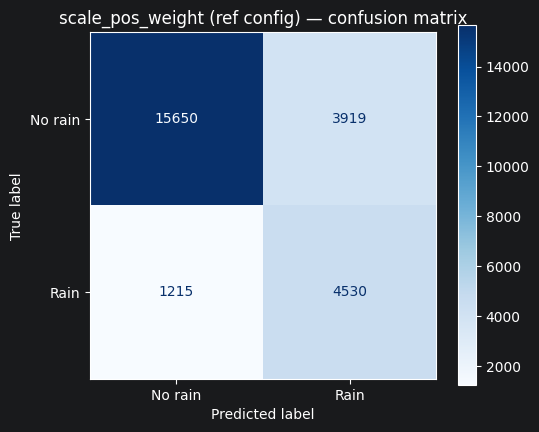

In [23]:
# Confusion matrix — scale_pos_weight
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm = confusion_matrix(y_test_i, p2)
ConfusionMatrixDisplay(cm, display_labels=['No rain', 'Rain']).plot(cmap='Blues', ax=ax)
ax.set_title('scale_pos_weight (ref config) — confusion matrix')
plt.tight_layout()
save_fig('02_scale_pos_weight_confusion_matrix', fig)
plt.show()

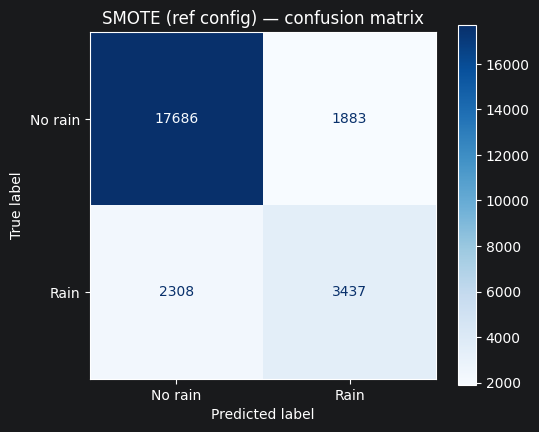

In [24]:
# Confusion matrix — SMOTE
if m3 is not None and p3 is not None:
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    cm = confusion_matrix(y_test_i, p3)
    ConfusionMatrixDisplay(cm, display_labels=['No rain', 'Rain']).plot(cmap='Blues', ax=ax)
    ax.set_title('SMOTE (ref config) — confusion matrix')
    plt.tight_layout()
    save_fig('03_smote_confusion_matrix', fig)
    plt.show()
else:
    print('SMOTE confusion matrix skipped (imblearn unavailable).')

## 8. Threshold selection on training folds (TimeSeriesSplit)

PR-crossover criterion $D(t)=|P-F_1|+|F_1-R|$, minimized over `TimeSeriesSplit` validation
folds. The grid is **re-derived over [0.10, 0.80]** rather than inherited from the LR study,
whose narrow [0.60, 0.80] range was a consequence of `class_weight='balanced'` probability
inflation. The crossover is located empirically for the tree.

In [25]:
log_section('8. Threshold selection (TimeSeriesSplit CV)')

thresholds = np.round(np.arange(0.10, 0.81, 0.01), 2)

fold_records = []
for tr_idx, val_idx in ts_cv.split(X_train):
    fm = XGBClassifier(**best_model.get_params())
    fm.fit(X_train.iloc[tr_idx], y_train_i.iloc[tr_idx])
    fold_records.append((
        y_train_i.iloc[val_idx].values,
        fm.predict_proba(X_train.iloc[val_idx])[:, 1],
    ))

rows = []
for t in thresholds:
    f1s = [f1_score(yt, yp >= t) for yt, yp in fold_records]
    precs = [precision_score(yt, yp >= t, zero_division=0) for yt, yp in fold_records]
    recs = [recall_score(yt, yp >= t) for yt, yp in fold_records]
    rows.append({'threshold': t, 'CV_F1_mean': np.mean(f1s), 'CV_F1_std': np.std(f1s),
                 'CV_precision': np.mean(precs), 'CV_recall': np.mean(recs)})
thresh_df = pd.DataFrame(rows)

In [26]:
thresh_df['diff'] = abs(thresh_df['CV_precision'] - thresh_df['CV_F1_mean']) + abs(thresh_df['CV_F1_mean'] - thresh_df['CV_recall'])

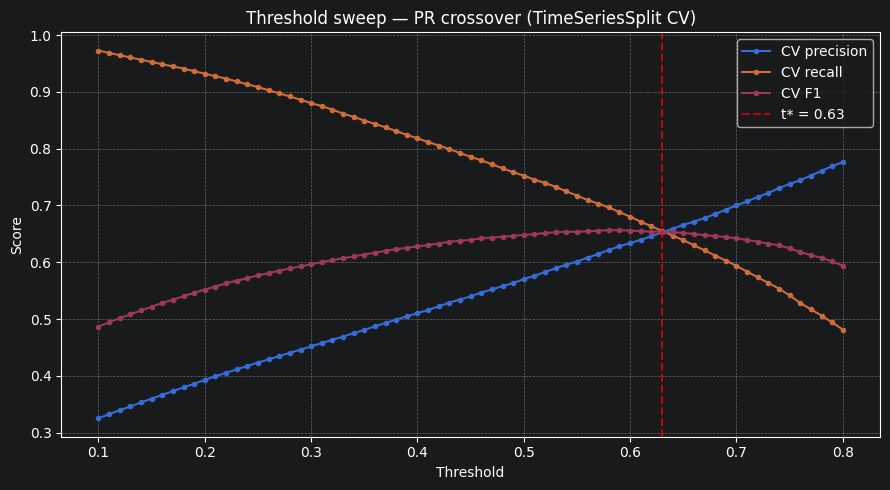

In [27]:
best_threshold = float(thresh_df.loc[thresh_df['diff'].idxmin(), 'threshold'])
print(f'CV-selected threshold: {best_threshold}')
print('\nThreshold sweep table (every 5th row):')
print(thresh_df.iloc[::5].to_string(index=False, float_format='%.4f'))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresh_df['threshold'], thresh_df['CV_precision'], 'o-', label='CV precision', ms=3)
ax.plot(thresh_df['threshold'], thresh_df['CV_recall'], 'o-', label='CV recall', ms=3)
ax.plot(thresh_df['threshold'], thresh_df['CV_F1_mean'], 'o-', label='CV F1', ms=3)
ax.axvline(best_threshold, color='red', linestyle='--', alpha=0.7, label=f't* = {best_threshold}')
ax.set_xlabel('Threshold'); ax.set_ylabel('Score')
ax.set_title('Threshold sweep — PR crossover (TimeSeriesSplit CV)')
ax.legend(); ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
save_fig('04_threshold_sweep', fig)
plt.show()

# Test evaluation at t*
y_pred_thr = (y_proba_tuned >= best_threshold).astype(int)
print(f'\nTest evaluation at threshold {best_threshold}:')
print(classification_report(y_test_i, y_pred_thr))

save_model(best_model, 'EXP-001_06_tuned_with_threshold',
           features=FEATURES, stage='tuned model + PR-crossover threshold (CV-selected)',
           threshold=best_threshold, best_params=best_params,
           threshold_sweep=thresh_df)


## 9. Feature importance & SHAP attribution

Trees have no signed coefficients, so the LR bootstrap-CI analysis is replaced by
gain-based importance and SHAP values [Lundberg & Lee, 2017]. SHAP shows per-feature
contribution magnitude *and* direction; it is expected to confirm the dominant
`Humidity3pm` / `Pressure3pm` / `Sunshine` signal without the LR pressure-pair sign-flip
artifact (trees do not suffer multicollinearity-induced compensation).

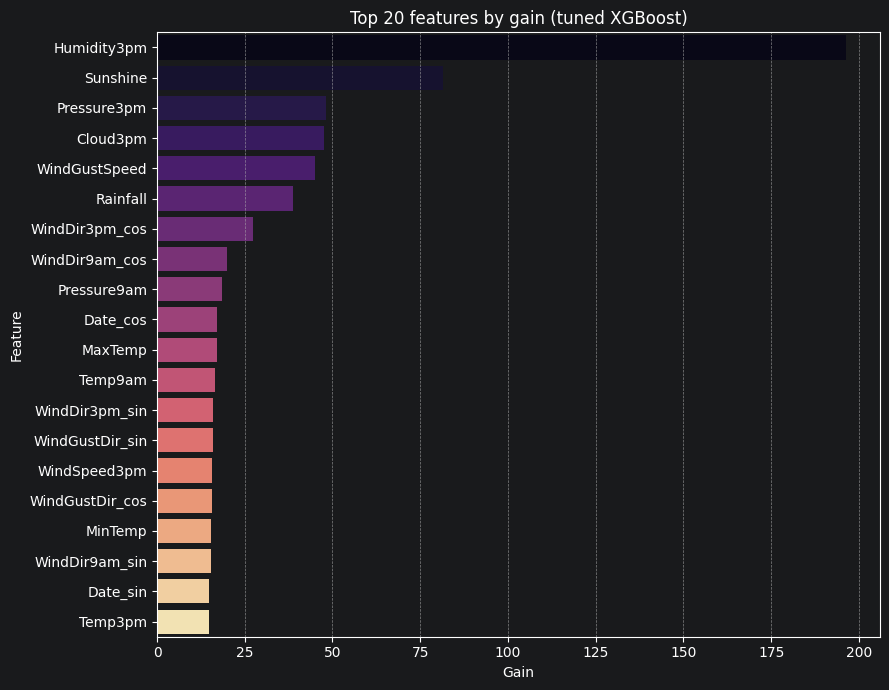

In [28]:
log_section('9. Feature importance & SHAP attribution')

# Gain-based importance from the tuned model.
booster = best_model.get_booster()
gain = booster.get_score(importance_type='gain')
imp_df = pd.DataFrame({
    'Feature': list(gain.keys()),
    'Gain': list(gain.values()),
}).sort_values('Gain', ascending=False).reset_index(drop=True)

print('Feature importance by gain (top 20):')
print(imp_df.head(20).to_string(index=False, float_format='%.2f'))

fig = plt.figure(figsize=(9, 7))
sns.barplot(data=imp_df.head(20), x='Gain', y='Feature',
            hue='Feature', palette='magma', legend=False)
plt.title('Top 20 features by gain (tuned XGBoost)')
plt.xlabel('Gain'); plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
save_fig('05_feature_importance_gain', fig)
plt.show()

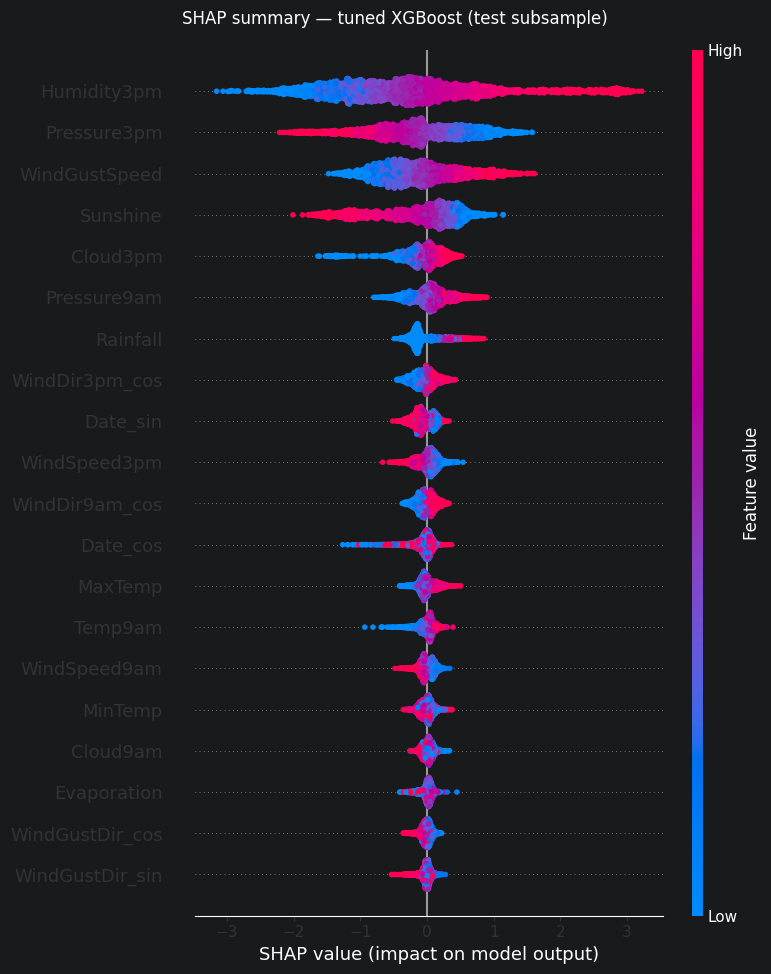

In [29]:
# SHAP summary (beeswarm). Subsample the test set for tractability.
# TreeExplainer uses the booster's GPU predictor when device="cuda", so this is fast.
if HAS_SHAP:
    try:
        n_shap = min(3000, X_test.shape[0])
        X_shap = X_test.sample(n=n_shap, random_state=RANDOM_STATE)
        explainer = shap.TreeExplainer(best_model)
        shap_values = explainer.shap_values(X_shap)

        plt.figure()
        shap.summary_plot(shap_values, X_shap, show=False)
        fig = plt.gcf()
        fig.suptitle('SHAP summary — tuned XGBoost (test subsample)', y=1.02)
        save_fig('06_shap_summary', fig)
        plt.show()

        mean_abs = pd.DataFrame({
            'Feature': X_shap.columns,
            'mean_abs_SHAP': np.abs(shap_values).mean(axis=0),
        }).sort_values('mean_abs_SHAP', ascending=False)
        print('\nMean |SHAP| ranking (top 15):')
        print(mean_abs.head(15).to_string(index=False, float_format='%.4f'))
    except Exception as e:
        print(f'SHAP computation failed ({type(e).__name__}: {e}); skipping.')
else:
    print('SHAP not installed — section limited to gain-based importance above.')

## 10. Calibration analysis

Boosting is typically miscalibrated out of the box. The LR recalibration machinery is
reused unchanged: reliability diagram, Brier, ECE, and post-hoc isotonic / Platt maps fit
on a chronological 85/15 refit-calibration split of the training period.

In [30]:
log_section('10. Calibration analysis')

def expected_calibration_error(y_true, y_prob, n_bins=10):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_idx = np.digitize(y_prob, bin_edges[1:-1])
    ece = 0.0
    n = len(y_true)
    for b in range(n_bins):
        mask = bin_idx == b
        if mask.sum() > 0:
            acc = y_true[mask].mean()
            conf = y_prob[mask].mean()
            ece += (mask.sum() / n) * abs(acc - conf)
    return ece

probs = {
    'baseline (no reweight)': y_proba_baseline,
    'tuned (best_model)':     y_proba_tuned,
}

calib_metrics = []
for name, p in probs.items():
    calib_metrics.append({
        'model':  name,
        'Brier':  brier_score_loss(y_test_i, p),
        'logloss': log_loss(y_test_i, np.clip(p, 1e-9, 1 - 1e-9)),
        'ECE_10': expected_calibration_error(y_test_i.values, p, n_bins=10),
        'mean_pred': float(np.mean(p)),
        'empirical_rate': float(y_test_i.mean()),
    })
calib_table = pd.DataFrame(calib_metrics).round(4)
print('\nCalibration metrics:')
print(calib_table.to_string(index=False))

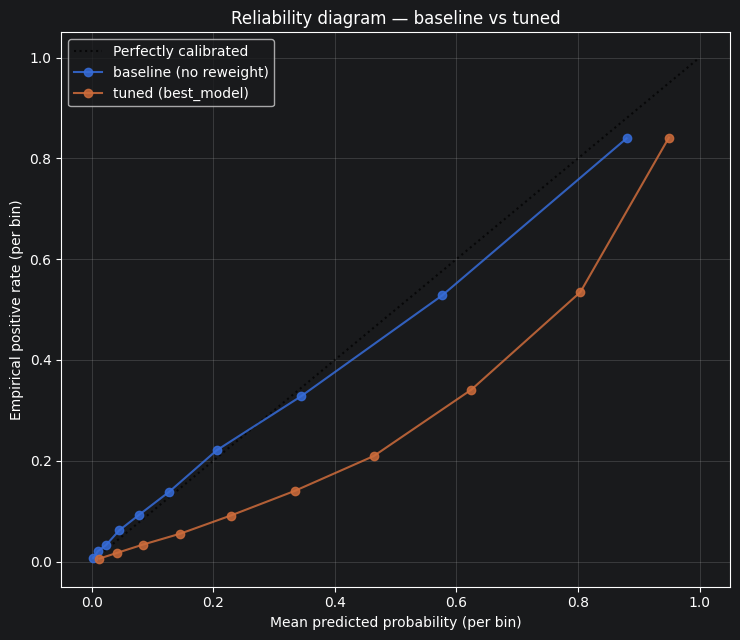

In [31]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.plot([0, 1], [0, 1], 'k:', label='Perfectly calibrated', alpha=0.7)
for name, p in probs.items():
    prob_true, prob_pred = calibration_curve(y_test_i, p, n_bins=10, strategy='quantile')
    ax.plot(prob_pred, prob_true, 'o-', label=name, alpha=0.85)
ax.set_xlabel('Mean predicted probability (per bin)')
ax.set_ylabel('Empirical positive rate (per bin)')
ax.set_title('Reliability diagram — baseline vs tuned')
ax.legend(loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('07_reliability_diagram', fig)
plt.show()

In [32]:
# Post-hoc recalibration: chronological 85/15 (refit, calibrate) split of the train period.
n_train = len(X_train)
calib_split = int(n_train * 0.85)
X_refit = X_train.iloc[:calib_split]
y_refit = y_train_i.iloc[:calib_split]
X_calib = X_train.iloc[calib_split:]
y_calib = y_train_i.iloc[calib_split:]

refit_model = XGBClassifier(**best_model.get_params())
refit_model.fit(X_refit, y_refit)

def make_calibrated(model, method, Xc, yc):
    """Calibrate a prefit model, handling both modern (FrozenEstimator) and
    legacy (cv='prefit') scikit-learn APIs."""
    try:
        from sklearn.frozen import FrozenEstimator
        cc = CalibratedClassifierCV(FrozenEstimator(model), method=method)
        cc.fit(Xc, yc)
        return cc
    except Exception:
        cc = CalibratedClassifierCV(model, method=method, cv='prefit')
        cc.fit(Xc, yc)
        return cc

calib_iso = make_calibrated(refit_model, 'isotonic', X_calib, y_calib)
calib_sig = make_calibrated(refit_model, 'sigmoid', X_calib, y_calib)

y_proba_iso = calib_iso.predict_proba(X_test)[:, 1]
y_proba_sig = calib_sig.predict_proba(X_test)[:, 1]

rows = []
for name, p in [('refit (uncalibrated)', refit_model.predict_proba(X_test)[:, 1]),
                ('isotonic recalibrated', y_proba_iso),
                ('sigmoid (Platt) recalibrated', y_proba_sig)]:
    rows.append({
        'method': name,
        'Brier':  brier_score_loss(y_test_i, p),
        'logloss': log_loss(y_test_i, np.clip(p, 1e-9, 1 - 1e-9)),
        'ECE_10': expected_calibration_error(y_test_i.values, p, n_bins=10),
        'mean_pred': float(np.mean(p)),
        'ROC_AUC': roc_auc_score(y_test_i, p),
    })
recalib_table = pd.DataFrame(rows).round(4)
print('\nPost-hoc recalibration metrics:')
print(recalib_table.to_string(index=False))

save_model(refit_model, 'EXP-001_07_refit_85pct',
           features=FEATURES, stage='refit on the chronological first 85% of train',
           best_params=best_params)
save_model(calib_iso, 'EXP-001_08_calibrated_isotonic',
           features=FEATURES, stage='isotonic recalibration on the last 15% of train',
           calibration_rows=int(len(X_calib)))
save_model(calib_sig, 'EXP-001_09_calibrated_sigmoid',
           features=FEATURES, stage='Platt (sigmoid) recalibration on the last 15% of train',
           calibration_rows=int(len(X_calib)))


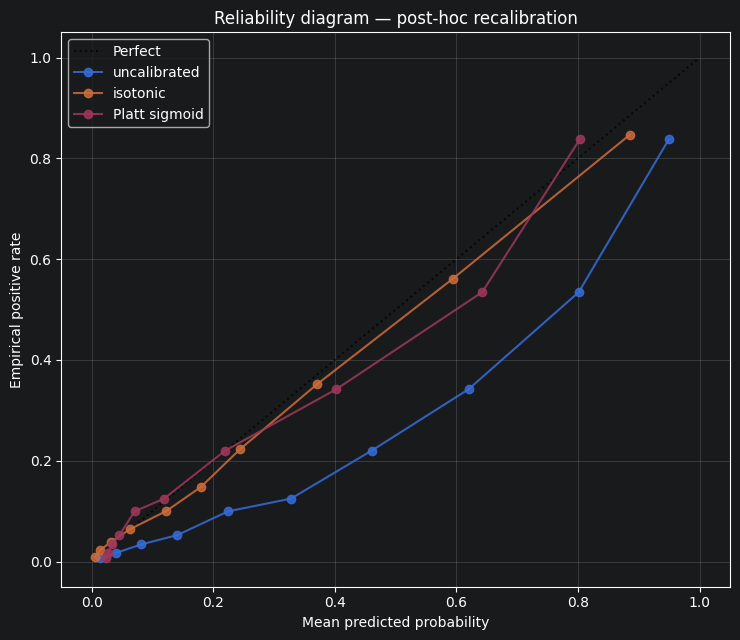

In [33]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.plot([0, 1], [0, 1], 'k:', alpha=0.7, label='Perfect')
for name, p in [('uncalibrated', refit_model.predict_proba(X_test)[:, 1]),
                ('isotonic', y_proba_iso),
                ('Platt sigmoid', y_proba_sig)]:
    prob_true, prob_pred = calibration_curve(y_test_i, p, n_bins=10, strategy='quantile')
    ax.plot(prob_pred, prob_true, 'o-', label=name, alpha=0.85)
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Empirical positive rate')
ax.set_title('Reliability diagram — post-hoc recalibration')
ax.legend(loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('08_recalibration_reliability_diagram', fig)
plt.show()

## 11. Final evaluation curves

ROC and PR curves on the chronological test set, plus a `TimeSeriesSplit` learning curve to
check whether XGBoost has capacity headroom over the linear plateau (CV F1 ≈ 0.61).

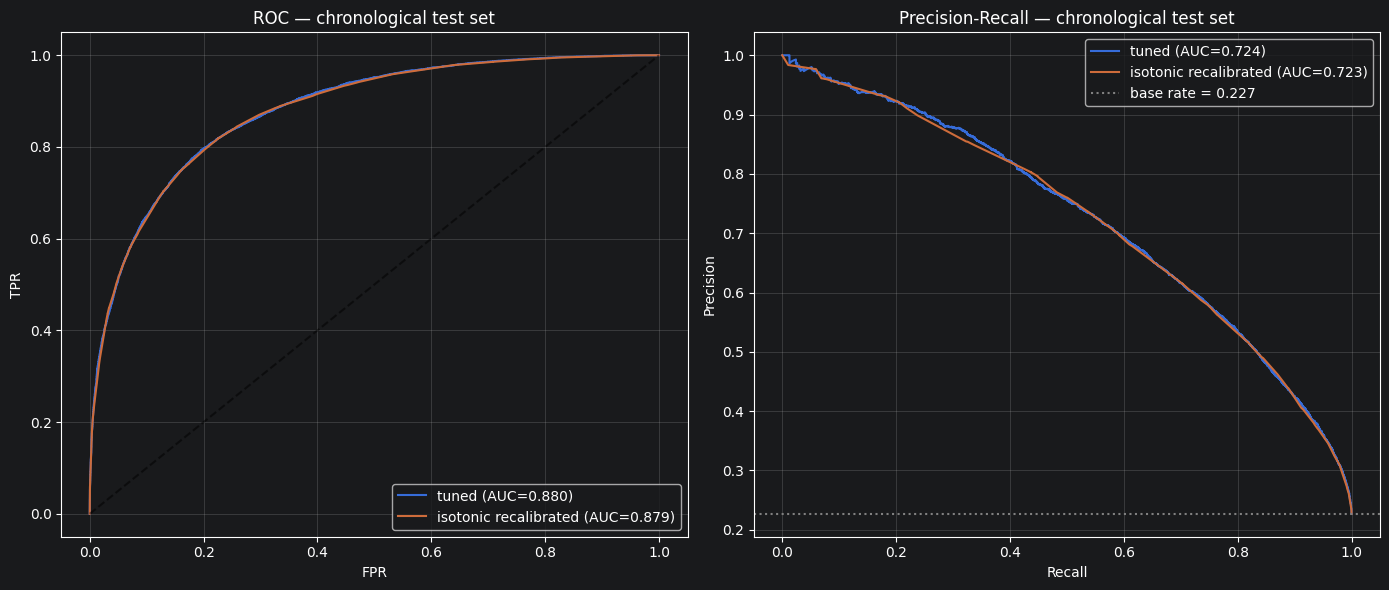

In [34]:
log_section('11. Final evaluation curves')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

roc_aucs = {}
for name, p in [('tuned', y_proba_tuned),
                ('isotonic recalibrated', y_proba_iso)]:
    fpr, tpr, _ = roc_curve(y_test_i, p)
    auc_v = roc_auc_score(y_test_i, p)
    roc_aucs[name] = auc_v
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc_v:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC — chronological test set')
axes[0].legend(loc='lower right'); axes[0].grid(alpha=0.3)

base_rate = float(y_test_i.mean())
pr_aucs = {}
for name, p in [('tuned', y_proba_tuned),
                ('isotonic recalibrated', y_proba_iso)]:
    pr, rc, _ = precision_recall_curve(y_test_i, p)
    pr_auc = auc(rc, pr)
    pr_aucs[name] = pr_auc
    axes[1].plot(rc, pr, label=f'{name} (AUC={pr_auc:.3f})')
axes[1].axhline(base_rate, color='gray', linestyle=':', label=f'base rate = {base_rate:.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall — chronological test set')
axes[1].legend(loc='upper right'); axes[1].grid(alpha=0.3)
plt.tight_layout()
save_fig('09_roc_pr_curves', fig)
plt.show()

print('\nROC-AUC by source:')
for name, v in roc_aucs.items():
    print(f'  {name:30s} {v:.4f}')
print('PR-AUC by source:')
for name, v in pr_aucs.items():
    print(f'  {name:30s} {v:.4f}')
print(f'Base rate (positive class fraction in test set): {base_rate:.4f}')

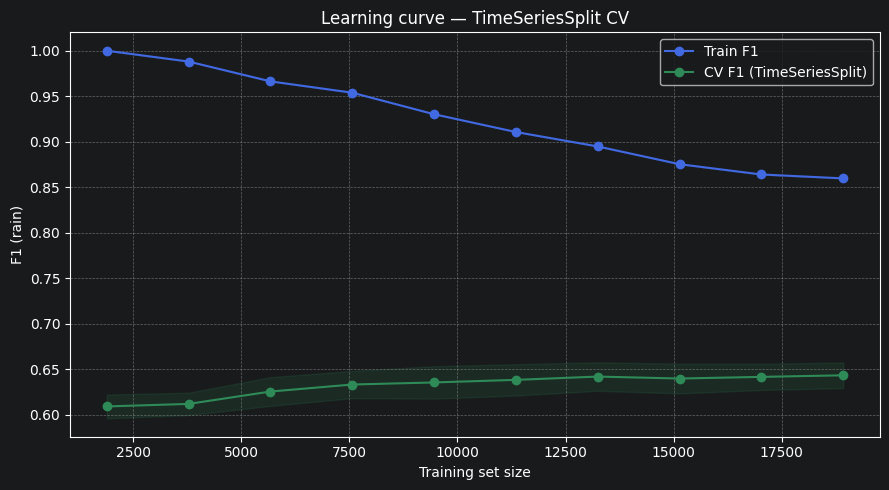

In [35]:
estimator = XGBClassifier(**best_model.get_params())
train_sizes, train_scores, val_scores = learning_curve(
    estimator, X_train, y_train_i,
    cv=ts_cv, scoring='f1', n_jobs=SEARCH_N_JOBS,
    train_sizes=np.linspace(0.1, 1.0, 10),
)
tr_m, tr_s = train_scores.mean(1), train_scores.std(1)
vl_m, vl_s = val_scores.mean(1), val_scores.std(1)

print('\nLearning curve — train and CV F1 by training set size:')
lc_df = pd.DataFrame({
    'train_size': train_sizes,
    'train_F1_mean': tr_m, 'train_F1_std': tr_s,
    'cv_F1_mean': vl_m, 'cv_F1_std': vl_s,
})
print(lc_df.to_string(index=False, float_format='%.4f'))

fig = plt.figure(figsize=(9, 5))
plt.plot(train_sizes, tr_m, 'o-', color='royalblue', label='Train F1')
plt.fill_between(train_sizes, tr_m - tr_s, tr_m + tr_s, alpha=0.15, color='royalblue')
plt.plot(train_sizes, vl_m, 'o-', color='seagreen', label='CV F1 (TimeSeriesSplit)')
plt.fill_between(train_sizes, vl_m - vl_s, vl_m + vl_s, alpha=0.15, color='seagreen')
plt.xlabel('Training set size'); plt.ylabel('F1 (rain)')
plt.title('Learning curve — TimeSeriesSplit CV')
plt.legend(); plt.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
save_fig('10_learning_curve', fig)
plt.show()

## Finalization

Restores stdout, closes the log, lists the artifacts, and (on Colab) zips
`XGB_result.txt` + `figures/` and triggers a browser download.

In [37]:
log_section('Finalization')

print(f'Results file: {_XGB_RESULT_PATH}')
fig_files = sorted(f for f in os.listdir('figures') if f.lower().endswith('.png'))
print(f'Figures saved ({len(fig_files)}):')
for f in fig_files:
    print(f'  figures/{f}')

model_files = sorted(f for f in os.listdir(MODEL_DIR) if f.startswith('EXP-001_'))
print(f'\nModels saved ({len(model_files)}) in {MODEL_DIR}:')
for f in model_files:
    print(f'  {f}')

# Restore stdout and close log file
sys.stdout = _ORIG_STDOUT
_XGB_RESULT_FILE.close()

# Bundle artifacts into a zip for download.
ZIP_PATH = 'XGBoost_artifacts.zip'
with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(_XGB_RESULT_PATH)
    for f in fig_files:
        zf.write(f'figures/{f}')
print(f'Bundled artifacts into {ZIP_PATH}')

# On Colab, trigger a browser download.
if IN_COLAB:
    from google.colab import files
    files.download(ZIP_PATH)

print(f'\nDone. See {_XGB_RESULT_PATH} and figures/ for outputs.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>